# Data Cleaning Notebook
This notebook includes the inspection and considerations we made for the selected datasets used in our project. 

Please note that this might include intermediate steps, and the final exported CSV files are served as the starting point for our visualizations and analysis.

## Import and Set-Up

In [1]:
from zipfile import ZipFile
import json
import urllib.request
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

## Load in Datasets

In [2]:
# Path is slightly adjusted for Midterm Submission
# Keep the GEOID Structure
income_pop = pd.read_csv("data_MT/ACS_income_pop.csv", dtype={
        "state": str,
        "county": str,
        "tract": str
    })

tracts = gpd.read_file("data_MT/tl_2024_06_tract.zip")
places = gpd.read_file("data_MT/tl_2024_06_place.zip")

# GTFS Data 2026
with ZipFile("../data/raw/gtfs_bus_2026.zip") as feed:
    bus_stops_2026 = pd.read_csv(feed.open("stops.txt"))

with ZipFile("../data/raw/gtfs_rail_2026.zip") as feed:
    rail_stops_2026 = pd.read_csv(feed.open("stops.txt"))

# GTFS Data 2020
with ZipFile("../data/raw/gtfs_bus_2020.zip") as feed:
    bus_stops_2020 = pd.read_csv(feed.open("stops.txt"))

with ZipFile("../data/raw/gtfs_rail_2020.zip") as feed:
    rail_stops_2020 = pd.read_csv(feed.open("stops.txt"))
# Note: We used the Census API to extract the ACS 5-year estimate, but to avoid requesting the API in this notebook, we saved the
# results in a CSV file.

ERROR 1: PROJ: proj_create_from_database: Open of /srv/conda/envs/notebook/share/proj failed


## ACS Data Processing

In [3]:
# Make GEOID on ACS data to join with tracts
income_pop["GEOID"] = income_pop["state"] + income_pop["county"] + income_pop["tract"]

# make sure attributes are correct data type before joining
tracts["GEOID"] = tracts["GEOID"].astype(str)
income_pop["GEOID"] = income_pop["GEOID"].astype(str)
income_pop["B01003_001E"] = income_pop["B01003_001E"].astype(int)
income_pop["B19013_001E"] = income_pop["B19013_001E"].astype(float)

In [4]:
tracts_income = tracts.merge(income_pop, on="GEOID", how="inner").copy()

# Only keep essential columns for our analysis
tracts_income = tracts_income.loc[:,["GEOID", "NAME_x", "B01003_001E", "B19013_001E", "INTPTLAT", "INTPTLON", "geometry"]]

# rename columns
names = {
    "NAME_x": "Tract_Name",
    "B01003_001E": "Total_Population",
    "B19013_001E": "Median_Household_Income"
}

tracts_income = tracts_income.rename(columns=names)
tracts_income.head()

,GEOID,Tract_Name,Total_Population,Median_Household_Income,INTPTLAT,INTPTLON,geometry
0,06037204920,2049.20,2274,75972.0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
1,06037205110,2051.10,3501,54939.0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
2,06037205120,2051.20,3252,32406.0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."
3,06037206010,2060.10,3392,70304.0,+34.0682177,-118.2320356,"POLYGON ((-118.23924 34.06726, -118.238 34.067..."
4,06037206020,2060.20,7629,155658.0,+34.0571230,-118.2311021,"POLYGON ((-118.23787 34.05427, -118.23784 34.0..."


### Fix Income with No Estiamte to NAN

In [5]:
tracts_income["Median_Household_Income"] = tracts_income["Median_Household_Income"].replace(
    -666666666, np.nan)

## GTFS Data Processing

### Inspect to see if they have missing records on the IDs that will be used to join datasets

In [6]:
paths = {
    "bus2020": "data_MT/gtfs_bus_2020.zip",
    "bus2026": "data_MT/gtfs_bus_2026.zip",
    "rail2020": "data_MT/gtfs_rail_2020.zip",
    "rail2026": "data_MT/gtfs_rail_2026.zip"
}

files_names = ["stops.txt", "routes.txt", "trips.txt", "stop_times.txt", "calendar.txt", "calendar_dates.txt", "shapes.txt"]

In [7]:
for name, path in paths.items():
    print("="*20)
    print(f"GTFS of: {name}")

    with ZipFile(path) as feed:
        print("="*20)
        for file in files_names:
            data = pd.read_csv(feed.open(file))

            print("="*20)
            print(f"For {file}:")
            print("Rows:", len(data))
            print("Columns:", data.columns.tolist())
            
            print("Missing Counts:")
            print(data.isna().sum().to_dict())

# Expand the output for complete results

GTFS of: bus2020
For stops.txt:
Rows: 13807
Columns: ['stop_id', 'stop_code', 'stop_name', 'stop_desc', 'stop_lat', 'stop_lon', 'stop_url', 'location_type', 'parent_station', 'tpis_name']
Missing Counts:
{'stop_id': 0, 'stop_code': 0, 'stop_name': 0, 'stop_desc': 13807, 'stop_lat': 0, 'stop_lon': 0, 'stop_url': 13807, 'location_type': 13807, 'parent_station': 13807, 'tpis_name': 13807}
For routes.txt:
Rows: 133
Columns: ['route_id', 'route_short_name', 'route_long_name', 'route_desc', 'route_type', 'route_color', 'route_text_color', 'route_url']
Missing Counts:
{'route_id': 0, 'route_short_name': 2, 'route_long_name': 0, 'route_desc': 0, 'route_type': 0, 'route_color': 112, 'route_text_color': 112, 'route_url': 131}
For trips.txt:
Rows: 27260
Columns: ['route_id', 'service_id', 'trip_id', 'trip_headsign', 'direction_id', 'block_id', 'shape_id']
Missing Counts:
{'route_id': 0, 'service_id': 0, 'trip_id': 0, 'trip_headsign': 27260, 'direction_id': 0, 'block_id': 0, 'shape_id': 0}
For sto

/tmp/ipykernel_141/1542662831.py:8: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(feed.open(file))


For stop_times.txt:
Rows: 2106179
Columns: ['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'stop_headsign', 'pickup_type', 'drop_off_type', 'trip_id_event', 'route_code', 'destination_code', 'timepoint', 'bay_num']
Missing Counts:
{'trip_id': 0, 'arrival_time': 0, 'departure_time': 0, 'stop_id': 0, 'stop_sequence': 0, 'stop_headsign': 0, 'pickup_type': 0, 'drop_off_type': 0, 'trip_id_event': 0, 'route_code': 0, 'destination_code': 0, 'timepoint': 0, 'bay_num': 2085517}
For calendar.txt:
Rows: 129
Columns: ['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']
Missing Counts:
{'service_id': 0, 'monday': 0, 'tuesday': 0, 'wednesday': 0, 'thursday': 0, 'friday': 0, 'saturday': 0, 'sunday': 0, 'start_date': 0, 'end_date': 0}
For calendar_dates.txt:
Rows: 7086
Columns: ['service_id', 'date', 'exception_type']
Missing Counts:
{'service_id': 0, 'date': 0, 'exception_type': 0}
For shapes.txt:
Rows: 344948

### Merge Bus and Rail stops

In [8]:
# Make a new column to differentiate Bus & Rail Stops
bus_stops_2026["mode"] = "bus"
rail_stops_2026['mode'] = "rail"

bus_stops_2020["mode"] = "bus"
rail_stops_2020['mode'] = "rail"

# Merge
stops_2026 = pd.concat([bus_stops_2026, rail_stops_2026], ignore_index=True)
stops_2020 = pd.concat([bus_stops_2020, rail_stops_2020], ignore_index=True)

# Select the essential columns
all_stops_2026 = stops_2026.copy().loc[:, ["stop_id", "stop_name", "stop_lat", "stop_lon", "mode"]]
all_stops_2020 = stops_2020.copy().loc[:, ["stop_id", "stop_name", "stop_lat", "stop_lon", "mode"]]

print(f"2026 GTFS Stop Summary:")
print(f"# of Bus stops: {len(bus_stops_2026)}, Rail stops: {len(rail_stops_2026)}, Combined: {len(all_stops_2026)}.")
display(all_stops_2026.head())

print(f"2020 GTFS Stop Summary:")
print(f"# of Bus stops: {len(bus_stops_2020)}, Rail stops: {len(rail_stops_2020)}, Combined: {len(all_stops_2020)}.")
display(all_stops_2020.head())

2026 GTFS Stop Summary:
# of Bus stops: 11892, Rail stops: 463, Combined: 12355.


,stop_id,stop_name,stop_lat,stop_lon,mode
0,1,Paramount / Slauson,33.973248,-118.113113,bus
1,3,Jefferson / 10th,34.025471,-118.328402,bus
2,6,120th / Augustus F Hawkins,33.924696,-118.242222,bus
3,7,120th / Martin Luther King Hospital,33.924505,-118.240369,bus
4,12,15054 Sherman Way,34.201075,-118.461953,bus


2020 GTFS Stop Summary:
# of Bus stops: 13807, Rail stops: 394, Combined: 14201.


,stop_id,stop_name,stop_lat,stop_lon,mode
0,1,Paramount / Slauson,33.973248,-118.113113,bus
1,3,Jefferson / 10th,34.025471,-118.328402,bus
2,6,120th / Augustus F Hawkins,33.924696,-118.242222,bus
3,7,120th / Martin Luther King Hospital,33.924505,-118.240369,bus
4,8,120th / Crenshaw,33.923818,-118.326886,bus


### Convert GTFS to GeoDataFrame

In [9]:
# CRS needs to be EPSG:4629 to ensure consistency with Tracts Data
stops_2026_gdf = gpd.GeoDataFrame(all_stops_2026, 
                             geometry = gpd.points_from_xy(all_stops_2026["stop_lon"],all_stops_2026["stop_lat"]),
                             crs = "EPSG:4269")

stops_2020_gdf = gpd.GeoDataFrame(all_stops_2020, 
                             geometry = gpd.points_from_xy(all_stops_2020["stop_lon"],all_stops_2020["stop_lat"]),
                             crs = "EPSG:4269")

In [24]:
stops_2026_gdf.to_csv("../data/processed/GTFS_stops_2026.csv")
stops_2020_gdf.to_csv("../data/processed/GTFS_stops_2020.csv")

## TIGER Boundary Processing

### Filter the `places` to only City of LA

In [10]:
la = places.copy()

la_mask = la['NAME'].str.strip() == "Los Angeles"
la = la[la_mask]
la

,STATEFP,PLACEFP,PLACENS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,PCICBSA,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
138,06,44000,02410877,0644000,1600000US0644000,Los Angeles,Los Angeles city,25,C1,Y,G4110,A,1218641632,80409616,+34.0193936,-118.4108248,"POLYGON ((-118.66818 34.18987, -118.66815 34.1..."


### Spatially Intersects with ACS to find Tracts that are in the City

In [11]:
# Extract the City of LA Boundary
city_bound = la.geometry.union_all()

# Also filter out the ones that could be partially in the boundary
intersecting = tracts_income[tracts_income.intersects(city_bound)]
within = tracts_income[tracts_income.within(city_bound)]
partial = intersecting.loc[~intersecting.index.isin(within.index)].copy()

print("Tracts intersecting the city:", len(intersecting))
print("Tracts fully within the city:", len(within))
print("Intersecting but not fully within:", len(partial))

Tracts intersecting the city: 1305
Tracts fully within the city: 1096
Intersecting but not fully within: 209


## Analysis to determine whether to include partial Tracts or not
### Using Total Population from ACS Estiamtes

In [12]:
pop_col = "Total_Population"

within_pop = within[pop_col].sum()
partial_pop = partial[pop_col].sum()
intersecting_pop = intersecting[pop_col].sum()

# Summary Table including Tract Count and Previously Computed Population Total and Share.
summary = pd.DataFrame({
    "Group": ["Fully Within", "Partial", "All Intersecting"],
    "Tract_Count": [
        len(within),
        len(partial),
        len(intersecting)
    ],
    "Population": [
        within_pop,
        partial_pop,
        intersecting_pop
    ]
})

summary["Population_Share"] = (
    summary["Population"] / intersecting_pop * 100
)

display(summary)

,Group,Tract_Count,Population,Population_Share
0,Fully Within,1096,3804790,81.940184
1,Partial,209,838585,18.059816
2,All Intersecting,1305,4643375,100.000000


Looking at populations, it seems like we will be missing about 800k people who lived in the partial tracts, which is about 18.06% of the population out of all intersecting tracts. From this perspective, we should consider including them in our analysis. Let's further inspect these metrics.

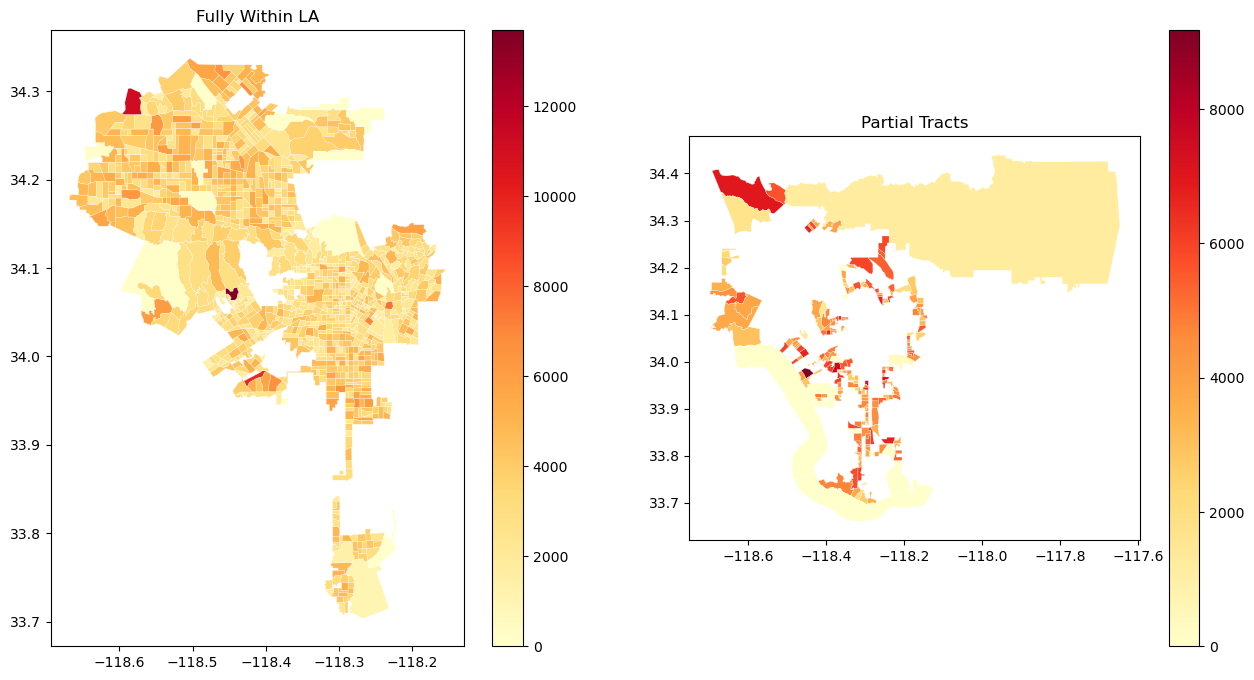

In [13]:
# Visually inspect where the population is spread in the Tracts
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Fully contained tracts
within.plot(
    column=pop_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[0],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[0].set_title("Fully Within LA")

# Partial tracts
partial.plot(
    column=pop_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[1],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[1].set_title("Partial Tracts")
plt.show()

Using tables and maps, we numerically and visually inspect how excluding the partial tracts might have an effect in terms of population we are missing in the analysis. However, we should also consider using `Median Household Income` since this socioeconomic factor will be used as part of our analysis; therefore, if there are tracts that don't have available income data, we should consider removing those first. In addition, we should also consider bringing in our main datasets - GTFS Schedule Data since if there are Tracts that don't have any bus/rail stops, this is also a factor to consider when excluding them from our analysis. 

### Using Median Household Income from ACS Estimates

In [14]:
income_col = "Median_Household_Income"

within_income = within[income_col]
partial_income = partial[income_col]
intersecting_income = intersecting[income_col]

income_summary = pd.DataFrame({
    "Group": ["Fully Within", "Partial", "All Intersecting"],
    "Tract_Count": [len(within), len(partial), len(intersecting)],
    "Valid_Tract_Count": [
        within[income_col].count(),
        partial[income_col].count(),
        intersecting[income_col].count(),
    ],
    "Mean_Income": [
        within_income.mean(),
        partial_income.mean(),
        intersecting_income.mean()
    ],
    "Median_Income": [
        within_income.median(),
        partial_income.median(),
        intersecting_income.median()
    ]
})

display(income_summary)

,Group,Tract_Count,Valid_Tract_Count,Mean_Income,Median_Income
0,Fully Within,1096,1080,87983.610185,79406.5
1,Partial,209,195,109749.364103,99806.0
2,All Intersecting,1305,1275,91312.490196,83270.0


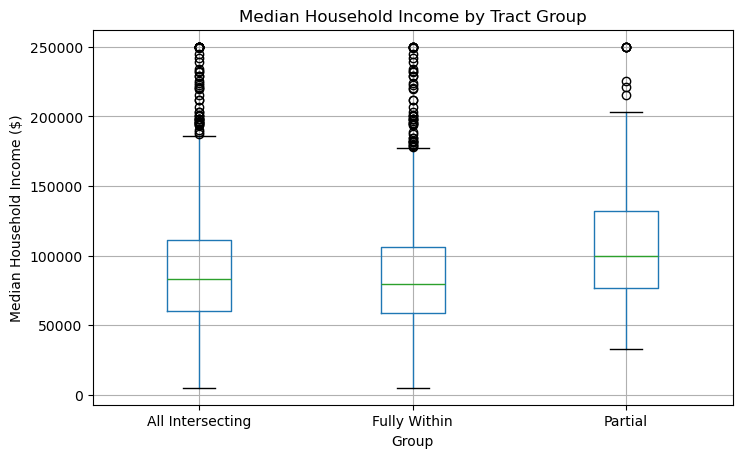

In [15]:
income_comparison = pd.DataFrame({
    "Income": pd.concat([
        within[income_col],
        partial[income_col],
        intersecting[income_col]
    ]),
    "Group": (
        ["Fully Within"] * len(within)
        + ["Partial"] * len(partial)
        + ["All Intersecting"] * len(intersecting)
    )
})

income_comparison.boxplot(
    column="Income",
    by="Group",
    figsize=(8, 5)
)

plt.title("Median Household Income by Tract Group")
plt.suptitle("")
plt.ylabel("Median Household Income ($)")
plt.show()

After numerically and visually inspecting the difference between each tract group in terms of median household income, we could conclude that partially overlapped tracts overall have a higher median household income compared with the other two groups, but it is inconclusive to exclude them from part of the analysis. 

### Using GTFS Schedule Data

In [16]:
la_stops_2026_gdf = stops_2026_gdf[stops_2026_gdf.within(city_bound)].copy()
la_stops_2020_gdf = stops_2020_gdf[stops_2020_gdf.within(city_bound)].copy()

In [17]:
# Spatial Join Bus/Rail Stops in LA City with Partial Census Tracts
partial_stop_2026_join = gpd.sjoin(
    la_stops_2026_gdf,
    partial[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

partial_stop_2020_join = gpd.sjoin(
    la_stops_2020_gdf,
    partial[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

In [18]:
# Quick Summary
print(f"2026 Summary:")
print("Stops by mode:")
print(partial_stop_2026_join["mode"].value_counts())

print("\nUnique partial tracts with stops:")
print(partial_stop_2026_join["GEOID"].nunique())

print("\nPartial tracts without stops:")
print(len(partial) - partial_stop_2026_join["GEOID"].nunique())

print("="*30)
print(f"2020 Summary:")
print("Stops by mode:")
print(partial_stop_2020_join["mode"].value_counts())

print("\nUnique partial tracts with stops:")
print(partial_stop_2020_join["GEOID"].nunique())

print("\nPartial tracts without stops:")
print(len(partial) - partial_stop_2020_join["GEOID"].nunique())

2026 Summary:
Stops by mode:
mode
bus     93
rail     5
Name: count, dtype: int64

Unique partial tracts with stops:
11

Partial tracts without stops:
198
2020 Summary:
Stops by mode:
mode
bus     104
rail      5
Name: count, dtype: int64

Unique partial tracts with stops:
11

Partial tracts without stops:
198


With this initial summary, we could notice that both 2020 and 2026 have 11 unique partially overlapped tracts with bus/rail stops, and 198 tracts without bus/rail stops. These 11 tracts are likely the same for both periods.

In [19]:
# Inspect the 11 tracts with stops
partial_with_stops_2026 = partial.merge(
    partial_stop_2026_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="inner"
)

display(partial_with_stops_2026[ ["GEOID", pop_col, income_col] ])

partial_with_stops_2020 = partial.merge(
    partial_stop_2020_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="inner"
)

display(partial_with_stops_2020[ ["GEOID", pop_col, income_col] ])
same_tract = partial_with_stops_2020["GEOID"] == partial_with_stops_2026["GEOID"]
print(f"Is the 11 Tracts the same for both periods?")
print(same_tract)

,GEOID,Total_Population,Median_Household_Income
0,06037275605,2915,119783.0
1,06037980028,0,NaN
2,06037297501,2697,168942.0
3,06037135205,2067,156389.0
4,06037292001,4522,54319.0
5,06037104124,3950,83958.0
6,06037278102,2917,174167.0
7,06037297601,3579,90556.0
8,06037104204,3577,76250.0
9,06037274202,4286,116552.0


,GEOID,Total_Population,Median_Household_Income
0,06037275605,2915,119783.0
1,06037980028,0,NaN
2,06037297501,2697,168942.0
3,06037135205,2067,156389.0
4,06037292001,4522,54319.0
5,06037104124,3950,83958.0
6,06037278102,2917,174167.0
7,06037297601,3579,90556.0
8,06037104204,3577,76250.0
9,06037274202,4286,116552.0


Is the 11 Tracts the same for both periods?
0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
Name: GEOID, dtype: bool


In [20]:
# Identify partial tracts without transit stops; since the tracts would be the same, we would do this once
partial_without_stops = partial.merge(
    partial_stop_2026_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="left",
    indicator=True
)

partial_without_stops = partial_without_stops[
    partial_without_stops["_merge"] == "left_only"
].copy()

# Compare the two groups
comparison = pd.DataFrame({
    "Group": ["With Stops", "Without Stops"],
    "Tract_Count": [
        len(partial_with_stops_2026),
        len(partial_without_stops)
    ],
    "Total_Population": [
        partial_with_stops_2026[pop_col].sum(),
        partial_without_stops[pop_col].sum()
    ],
    "Median_Population": [
        partial_with_stops_2026[pop_col].median(),
        partial_without_stops[pop_col].median()
    ],
    "Median_HH_Income": [
        partial_with_stops_2026[income_col].median(),
        partial_without_stops[income_col].median()
    ]
})

display(comparison)

,Group,Tract_Count,Total_Population,Median_Population,Median_HH_Income
0,With Stops,11,34319,3577.0,117718.5
1,Without Stops,198,804266,4165.5,99750.0


After inspecting the partially overlapping tracts with stops, we decided we would provisonally keep these tracts because accessibility could also be determine through walking accessbility. Therefore, those tracts that might not have service could still have the option to walk to the nearest stop.

### GeoDataFrame that contain all intersecting tracts stops

In [36]:
intersecting_stops_2026_gdf = gpd.sjoin(
    stops_2026_gdf,
    intersecting[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

intersecting_stops_2020_gdf = gpd.sjoin(
    stops_2020_gdf,
    intersecting[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

## Final Results

In [21]:
# This contains all intersecting Tracts of ACS Data
intersecting_acs = intersecting.copy()
display(intersecting.head(3))

# This contains all intersecting Tracts of GTFS data for 2026 and 2020

display(la_stops_2026_gdf.head(3))
display(la_stops_2020_gdf.head(3))

# This is the City of LA Boundary
display(la)

,GEOID,Tract_Name,Total_Population,Median_Household_Income,INTPTLAT,INTPTLON,geometry
0,06037204920,2049.20,2274,75972.0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
1,06037205110,2051.10,3501,54939.0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
2,06037205120,2051.20,3252,32406.0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."


,stop_id,stop_name,stop_lat,stop_lon,mode,geometry
1,3,Jefferson / 10th,34.025471,-118.328402,bus,POINT (-118.3284 34.02547)
4,12,15054 Sherman Way,34.201075,-118.461953,bus,POINT (-118.46195 34.20108)
5,16,Riverside / Los Feliz,34.116932,-118.271486,bus,POINT (-118.27149 34.11693)


,stop_id,stop_name,stop_lat,stop_lon,mode,geometry
1,3,Jefferson / 10th,34.025471,-118.328402,bus,POINT (-118.3284 34.02547)
7,12,15054 Sherman Way,34.201075,-118.461953,bus,POINT (-118.46195 34.20108)
10,16,Riverside / Los Feliz,34.116932,-118.271486,bus,POINT (-118.27149 34.11693)


,STATEFP,PLACEFP,PLACENS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,PCICBSA,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
138,06,44000,02410877,0644000,1600000US0644000,Los Angeles,Los Angeles city,25,C1,Y,G4110,A,1218641632,80409616,+34.0193936,-118.4108248,"POLYGON ((-118.66818 34.18987, -118.66815 34.1..."


In [22]:
intersecting_tracts = tracts[tracts.intersects(city_bound)]
display(intersecting_tracts.head(3))
print(intersecting_tracts.shape)

,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
2,06,037,204920,06037204920,1400000US06037204920,2049.20,Census Tract 2049.20,G5020,S,909972,0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
3,06,037,205110,06037205110,1400000US06037205110,2051.10,Census Tract 2051.10,G5020,S,286962,0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
4,06,037,205120,06037205120,1400000US06037205120,2051.20,Census Tract 2051.20,G5020,S,1466242,0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."


(1308, 14)


Although there are 1308 intersecting tracts if we used the TIGER tracts and spatially intersect with the TIGER City Boundary, we would instead use the ACS-matched 1305 tracts because we are mapping the socioeconomic factor, which is only available via the ACS 5-year estimate.

## Save the Results to CSV

In [40]:
# ACS Data
intersecting_acs.to_csv("data_MT/processed/ACS_income_pop_la_intersecting.csv")

# GTFS Stops inside City of LA for 2026 and 2020
la_stops_2026_gdf.to_csv("data_MT/processed/GTFS_stops_la_2026.csv")
la_stops_2020_gdf.to_csv("data_MT/processed/GTFS_stops_la_2020.csv")

# GTFS Stops in All Intersecting LA Tracts Data for 2026 and 2020
intersecting_stops_2026_gdf.to_csv("data_MT/processed/GTFS_stops_2026.csv")
intersecting_stops_2020_gdf.to_csv("data_MT/processed/GTFS_stops_2020.csv")

# City of LA Boundary
la.to_csv("data_MT/processed/la_boundary.csv")